# Lab 7: Đánh giá mô hình

Ghi chú: tệp `sinh_vien_bo_hoc.csv` không có kèm tài liệu nên được sinh mô phỏng theo đúng mô tả
(1200 sinh viên, khoảng 10% bỏ học, 4 cột đặc trưng). Vì vậy các con số khác tài liệu một chút.

## 2. Khi accuracy đánh lừa (h1_do_bua.py)

In [1]:
# -*- coding: utf-8 -*-
"""Bước 1: thấy accuracy đánh lừa trên dữ liệu lệch lớp."""

import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("sinh_vien_bo_hoc.csv")
print("Kich thuoc bang:", df.shape)
print(df.head())
print()
print("So sinh vien moi lop:")
print(df["bo_hoc"].value_counts().to_string())
print(f"Ty le bo hoc: {df['bo_hoc'].mean():.3f}")
print()

X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
# stratify=y giữ đúng tỷ lệ bỏ học ở cả tập học lẫn tập kiểm tra
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
print(f"Tap kiem tra: {len(y_te)} ban, {y_te.sum()} ban bo hoc")
print()

# Mô hình lười: ai cũng đoán là lớp đông nhất
luoi = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
du_luoi = luoi.predict(X_te)

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
du_lr = lr.predict(X_te)

for ten, du in [("Mo hinh luoi", du_luoi), ("Hoi quy logistic", du_lr)]:
    acc = accuracy_score(y_te, du)
    tim_ra = ((du == 1) & (y_te == 1)).sum()
    print(f"{ten:17s} accuracy {acc:.4f}, "
          f"tim ra {tim_ra} tren {y_te.sum()} ban bo hoc")

Kich thuoc bang: (1200, 5)
   diem_tb  so_buoi_vang  tin_chi_no  gio_lam_them  bo_hoc
0      8.0             3           0             0       0
1      8.9             5           1             7       0
2      3.3             3           1             4       0
3      6.4             3           0             7       0
4      7.9             3           5            23       0

So sinh vien moi lop:
bo_hoc
0    1081
1     119
Ty le bo hoc: 0.099

Tap kiem tra: 300 ban, 30 ban bo hoc

Mo hinh luoi      accuracy 0.9000, tim ra 0 tren 30 ban bo hoc
Hoi quy logistic  accuracy 0.9467, tim ra 17 tren 30 ban bo hoc


## 3. Ma trận nhầm lẫn (h2_ma_tran.py)

In [2]:
"""Bước 2: tự đếm bốn ô của ma trận nhầm lẫn, rồi so với thư viện."""

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
du = lr.fit(X_tr, y_tr).predict(X_te)
that = y_te.to_numpy()

# Tự đếm: mỗi ô là một cặp (nhãn thật, nhãn đoán)
tp = np.sum((that == 1) & (du == 1))
fp = np.sum((that == 0) & (du == 1))
fn = np.sum((that == 1) & (du == 0))
tn = np.sum((that == 0) & (du == 0))
print("Tu dem:")
print(f"  TP = {tp}  (doan bo hoc, dung la bo hoc)")
print(f"  FP = {fp}  (bao dong nham)")
print(f"  FN = {fn}  (bo sot)")
print(f"  TN = {tn}  (doan khong bo, dung la khong bo)")
print(f"  Tong = {tp + fp + fn + tn}")
print()

m = confusion_matrix(that, du)
print("confusion_matrix cua scikit-learn:")
print(m)
print("Thu tu khi trai ra: TN, FP, FN, TP =", m.ravel())
print()

acc = (tp + tn) / (tp + fp + fn + tn)
print(f"Accuracy tinh tu bon o: ({tp} + {tn}) / {len(that)} = {acc:.4f}")
print(f"So ban bi bao co nguy co: TP + FP = {tp + fp}")

Tu dem:
  TP = 17  (doan bo hoc, dung la bo hoc)
  FP = 3  (bao dong nham)
  FN = 13  (bo sot)
  TN = 267  (doan khong bo, dung la khong bo)
  Tong = 300

confusion_matrix cua scikit-learn:
[[267   3]
 [ 13  17]]
Thu tu khi trai ra: TN, FP, FN, TP = [267   3  13  17]

Accuracy tinh tu bon o: (17 + 267) / 300 = 0.9467
So ban bi bao co nguy co: TP + FP = 20


## 4. Precision, recall và F1 (h3_precision_recall.py)

In [3]:
"""Bước 3: precision, recall, F1 tính tay và tính bằng thư viện."""

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
du = lr.fit(X_tr, y_tr).predict(X_te)
tn, fp, fn, tp = confusion_matrix(y_te, du).ravel()

p = tp / (tp + fp)
r = tp / (tp + fn)
f1 = 2 * p * r / (p + r)
print("Tinh tay tu bon o:")
print(f"  Precision = {tp} / ({tp} + {fp}) = {p:.4f}")
print(f"  Recall    = {tp} / ({tp} + {fn}) = {r:.4f}")
print(f"  F1        = 2 x {p:.4f} x {r:.4f} / ({p:.4f} + {r:.4f})"
      f" = {f1:.4f}")
print()

print("Tinh bang scikit-learn:")
print(f"  Precision = {precision_score(y_te, du):.4f}")
print(f"  Recall    = {recall_score(y_te, du):.4f}")
print(f"  F1        = {f1_score(y_te, du):.4f}")
print()

print("Bao cao day du:")
print(classification_report(y_te, du, digits=4,
                            target_names=["khong bo", "bo hoc"]))

Tinh tay tu bon o:
  Precision = 17 / (17 + 3) = 0.8500
  Recall    = 17 / (17 + 13) = 0.5667
  F1        = 2 x 0.8500 x 0.5667 / (0.8500 + 0.5667) = 0.6800

Tinh bang scikit-learn:
  Precision = 0.8500
  Recall    = 0.5667
  F1        = 0.6800

Bao cao day du:
              precision    recall  f1-score   support

    khong bo     0.9536    0.9889    0.9709       270
      bo hoc     0.8500    0.5667    0.6800        30

    accuracy                         0.9467       300
   macro avg     0.9018    0.7778    0.8255       300
weighted avg     0.9432    0.9467    0.9418       300



## 5. Đổi ngưỡng quyết định (h4_nguong.py)

In [4]:
"""Bước 4: đổi ngưỡng, và chọn ngưỡng đúng cách trên tập học."""

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
xs = lr.predict_proba(X_te)[:, 1]      # xác suất bỏ học của từng bạn

print("Tap kiem tra, doi nguong")
print("nguong  so bao   TP  FP  FN   precision  recall    F1")
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    du = (xs >= t).astype(int)
    tp = int(((du == 1) & (y_te == 1)).sum())
    fp = int(((du == 1) & (y_te == 0)).sum())
    fn = int(((du == 0) & (y_te == 1)).sum())
    print(f"  {t:.1f}    {du.sum():4d}    {tp:3d} {fp:3d} {fn:3d}"
          f"    {precision_score(y_te, du):.4f}   "
          f"{recall_score(y_te, du):.4f}  {f1_score(y_te, du):.4f}")
print()

# Chọn ngưỡng đúng cách: chỉ dùng tập học, qua kiểm định chéo.
xs_hoc = cross_val_predict(lr, X_tr, y_tr, cv=5,
                           method="predict_proba")[:, 1]
cac_nguong = np.round(np.arange(0.05, 0.96, 0.05), 2)
f1_hoc = [f1_score(y_tr, (xs_hoc >= t).astype(int)) for t in cac_nguong]
t_tot = cac_nguong[int(np.argmax(f1_hoc))]
print(f"Nguong cho F1 cao nhat tren tap hoc: {t_tot}"
      f" (F1 kiem dinh cheo {max(f1_hoc):.4f})")

# Chọn xong mới dùng tập kiểm tra, và chỉ một lần
du = (xs >= t_tot).astype(int)
print(f"Tap kiem tra voi nguong {t_tot}:"
      f" precision {precision_score(y_te, du):.4f},"
      f" recall {recall_score(y_te, du):.4f},"
      f" F1 {f1_score(y_te, du):.4f}")

Tap kiem tra, doi nguong
nguong  so bao   TP  FP  FN   precision  recall    F1
  0.5      20     17   3  13    0.8500   0.5667  0.6800
  0.4      21     18   3  12    0.8571   0.6000  0.7059
  0.3      29     21   8   9    0.7241   0.7000  0.7119
  0.2      42     24  18   6    0.5714   0.8000  0.6667
  0.1      61     26  35   4    0.4262   0.8667  0.5714

Nguong cho F1 cao nhat tren tap hoc: 0.25 (F1 kiem dinh cheo 0.6473)
Tap kiem tra voi nguong 0.25: precision 0.6571, recall 0.7667, F1 0.7077


## 6. Đường ROC và AUC (h5_roc_auc.py)

In [5]:
"""Bước 5: đường ROC, AUC, và so các mô hình đã học trong môn."""

import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, recall_score, roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
xs = lr.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]

# Mỗi ngưỡng cho một điểm của đường ROC
fpr, tpr, nguong = roc_curve(y_te, xs)
print("Duong ROC co", len(fpr), "diem. Vai diem dau:")
print("  bao dong nham   recall")
for a, b in list(zip(fpr, tpr))[:6]:
    print(f"      {a:.4f}      {b:.4f}")
print(f"AUC cua logistic = {roc_auc_score(y_te, xs):.4f}")
print()

# So các mô hình đã học, cùng tập học, cùng tập kiểm tra
mo_hinh = {
    "Logistic": lr,
    "Naive Bayes": GaussianNB(),
    "KNN, k = 15": make_pipeline(StandardScaler(),
                                 KNeighborsClassifier(15)),
    "Cay sau 4": DecisionTreeClassifier(max_depth=4, random_state=0),
    "Rung 200 cay": RandomForestClassifier(200, random_state=0),
    "SVM RBF": make_pipeline(StandardScaler(),
                             SVC(probability=True, random_state=0)),
}
print("Mo hinh          AUC      recall    F1   (nguong 0.5)")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    p = mh.predict_proba(X_te)[:, 1]
    du = (p >= 0.5).astype(int)
    print(f"  {ten:14s} {roc_auc_score(y_te, p):.4f}   "
          f"{recall_score(y_te, du):.4f}  {f1_score(y_te, du):.4f}")

Duong ROC co 28 diem. Vai diem dau:
  bao dong nham   recall
      0.0000      0.0000
      0.0000      0.0333
      0.0000      0.4000
      0.0074      0.4000
      0.0074      0.5333
      0.0111      0.5333
AUC cua logistic = 0.9449

Mo hinh          AUC      recall    F1   (nguong 0.5)
  Logistic       0.9449   0.5667  0.6800
  Naive Bayes    0.9336   0.3667  0.5116
  KNN, k = 15    0.9274   0.2333  0.3684
  Cay sau 4      0.8803   0.4667  0.5957


  Rung 200 cay   0.9249   0.5667  0.6538
  SVM RBF        0.8996   0.5000  0.6250


## 7. Kiểm định chéo nhiều thước đo và cân bằng lớp (h6_can_bang.py)

In [6]:
"""Bước 6: kiểm định chéo với nhiều thước đo, và cân bằng lớp khi học."""

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]

# Chia không phân tầng: số bạn bỏ học trong tập kiểm tra dao động
print("Khong stratify, so ban bo hoc trong tap kiem tra:")
dem = []
for rs in range(10):
    _, _, _, y_te_thu = train_test_split(X, y, test_size=0.25,
                                         random_state=rs)
    dem.append(int(y_te_thu.sum()))
print(" ", dem)
print()

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
print("Kiem dinh cheo 5 phan tren tap hoc:")
for tm in ["accuracy", "precision", "recall", "f1"]:
    d = cross_val_score(lr, X_tr, y_tr, cv=5, scoring=tm)
    print(f"  {tm:10s} {d.mean():.4f}")
print()

# Cân bằng lớp: phạt nặng hơn khi đoán sai lớp hiếm
cb = make_pipeline(StandardScaler(),
                   LogisticRegression(class_weight="balanced"))
print("Tap kiem tra   precision  recall    F1")
for ten, mh in [("Binh thuong", lr), ("Can bang lop", cb)]:
    du = mh.fit(X_tr, y_tr).predict(X_te)
    print(f"  {ten:12s}  {precision_score(y_te, du):.4f}"
          f"    {recall_score(y_te, du):.4f}  {f1_score(y_te, du):.4f}")

Khong stratify, so ban bo hoc trong tap kiem tra:
  [22, 26, 35, 29, 32, 27, 28, 20, 27, 23]

Kiem dinh cheo 5 phan tren tap hoc:
  accuracy   0.9289
  precision  0.7044
  recall     0.4810


  f1         0.5652



Tap kiem tra   precision  recall    F1
  Binh thuong   0.8500    0.5667  0.6800
  Can bang lop  0.4483    0.8667  0.5909


## 8. Bài tập
### Bài tập 1: Tự viết hàm đánh giá

In [7]:
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def chia(tu, mau):
    # Quy ước giống zero_division=0 của scikit-learn: mẫu bằng 0 thì trả 0
    return tu / mau if mau > 0 else 0.0


def danh_gia(y_that, y_doan):
    y_that, y_doan = np.asarray(y_that), np.asarray(y_doan)
    tp = np.sum((y_that == 1) & (y_doan == 1))
    fp = np.sum((y_that == 0) & (y_doan == 1))
    fn = np.sum((y_that == 1) & (y_doan == 0))
    tn = np.sum((y_that == 0) & (y_doan == 0))
    acc = (tp + tn) / len(y_that)
    p = chia(tp, tp + fp)
    r = chia(tp, tp + fn)
    f1 = chia(2 * p * r, p + r)
    return acc, p, r, f1


df = pd.read_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
mo_hinh = {
    "Mo hinh luoi": DummyClassifier(strategy="most_frequent"),
    "Hoi quy logistic": make_pipeline(StandardScaler(), LogisticRegression()),
}
print("                      accuracy  precision  recall     F1")
for ten, mh in mo_hinh.items():
    du = mh.fit(X_tr, y_tr).predict(X_te)
    tu_viet = danh_gia(y_te, du)
    thu_vien = (accuracy_score(y_te, du),
                precision_score(y_te, du, zero_division=0),
                recall_score(y_te, du), f1_score(y_te, du))
    print(f"{ten:17s} tu viet  " + "   ".join(f"{v:.4f}" for v in tu_viet))
    print(f"{'':17s} sklearn  " + "   ".join(f"{v:.4f}" for v in thu_vien))
    assert np.allclose(tu_viet, thu_vien)

                      accuracy  precision  recall     F1
Mo hinh luoi      tu viet  0.9000   0.0000   0.0000   0.0000
                  sklearn  0.9000   0.0000   0.0000   0.0000
Hoi quy logistic  tu viet  0.9467   0.8500   0.5667   0.6800
                  sklearn  0.9467   0.8500   0.5667   0.6800


### Bài tập 2: Chữ số viết tay

In [8]:
from sklearn.datasets import load_digits
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
du = SVC(kernel="rbf").fit(X_tr, y_tr).predict(X_te)
print(classification_report(y_te, du, digits=4))

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.9787    1.0000    0.9892        46
           2     1.0000    1.0000    1.0000        44
           3     0.9787    1.0000    0.9892        46
           4     1.0000    0.9778    0.9888        45
           5     1.0000    1.0000    1.0000        46
           6     1.0000    1.0000    1.0000        45
           7     1.0000    0.9778    0.9888        45
           8     0.9767    0.9767    0.9767        43
           9     0.9778    0.9778    0.9778        45

    accuracy                         0.9911       450
   macro avg     0.9912    0.9910    0.9911       450
weighted avg     0.9912    0.9911    0.9911       450



### Bài tập 3: Chọn ngưỡng theo yêu cầu

In [9]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
lr = make_pipeline(StandardScaler(), LogisticRegression())

# Chỉ dùng tập học để chọn ngưỡng
xs_hoc = cross_val_predict(lr, X_tr, y_tr, cv=5, method="predict_proba")[:, 1]
cac_nguong = np.round(np.arange(0.01, 1.0, 0.01), 2)
dat = [t for t in cac_nguong if recall_score(y_tr, (xs_hoc >= t).astype(int)) >= 0.8]
t_chon = max(dat)
du_hoc = (xs_hoc >= t_chon).astype(int)
print(f"Nguong lon nhat cho recall >= 0.8 tren tap hoc: {t_chon}")
print(f"  recall kiem dinh cheo {recall_score(y_tr, du_hoc):.4f},"
      f" precision {precision_score(y_tr, du_hoc):.4f}")

# Áp một lần cho tập kiểm tra
xs = lr.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
du = (xs >= t_chon).astype(int)
print(f"Tap kiem tra voi nguong {t_chon}: recall {recall_score(y_te, du):.4f},"
      f" precision {precision_score(y_te, du):.4f},"
      f" so ban bi bao {du.sum()} tren {len(du)}"
      f" (that su bo hoc {y_te.sum()})")

Nguong lon nhat cho recall >= 0.8 tren tap hoc: 0.17
  recall kiem dinh cheo 0.8090, precision 0.5070
Tap kiem tra voi nguong 0.17: recall 0.8000, precision 0.5106, so ban bi bao 47 tren 300 (that su bo hoc 30)


### Bài tập 4: Tự vẽ đường ROC

Logistic: AUC = 0.9449


Rung 200 cay: AUC = 0.9249


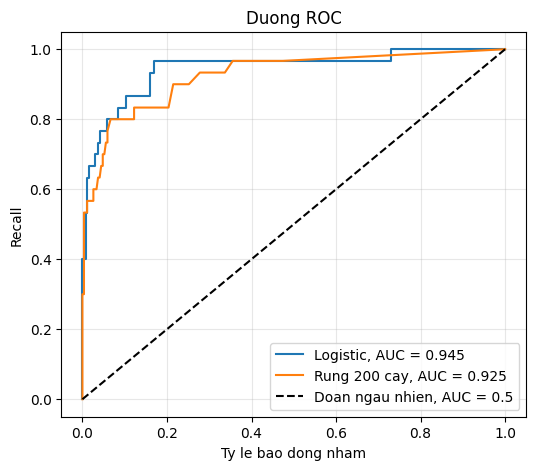

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
mo_hinh = {
    "Logistic": make_pipeline(StandardScaler(), LogisticRegression()),
    "Rung 200 cay": RandomForestClassifier(200, random_state=0),
}
plt.figure(figsize=(6, 5))
for ten, mh in mo_hinh.items():
    p = mh.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, p)
    auc = roc_auc_score(y_te, p)
    print(f"{ten}: AUC = {auc:.4f}")
    plt.plot(fpr, tpr, label=f"{ten}, AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "k--", label="Doan ngau nhien, AUC = 0.5")
plt.xlabel("Ty le bao dong nham")
plt.ylabel("Recall")
plt.title("Duong ROC")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("roc.png", dpi=120, bbox_inches="tight")
plt.show()

### Bài tập 5: Cân bằng lớp cho mô hình khác

In [11]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

df = pd.read_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
mo_hinh = {
    "Rung":            RandomForestClassifier(200, random_state=0),
    "Rung can bang":   RandomForestClassifier(200, random_state=0,
                                              class_weight="balanced"),
    "SVM":             make_pipeline(StandardScaler(), SVC()),
    "SVM can bang":    make_pipeline(StandardScaler(),
                                     SVC(class_weight="balanced")),
}
print("                 precision  recall    F1")
for ten, mh in mo_hinh.items():
    du = mh.fit(X_tr, y_tr).predict(X_te)
    print(f"  {ten:14s} {precision_score(y_te, du):.4f}    "
          f"{recall_score(y_te, du):.4f}  {f1_score(y_te, du):.4f}")

                 precision  recall    F1


  Rung           0.7727    0.5667  0.6538


  Rung can bang  0.7500    0.4000  0.5217
  SVM            0.8824    0.5000  0.6383
  SVM can bang   0.4464    0.8333  0.5814


### Bài tập 6: MAE và RMSE với một lần đoán hỏng

In [12]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("gia_nha.csv")
X = df[["dien_tich", "so_phong", "tuoi_nha"]]
y = df["gia"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17)
du = LinearRegression().fit(X_tr, y_tr).predict(X_te)


def ba_so(y_that, y_doan):
    return (mean_absolute_error(y_that, y_doan),
            np.sqrt(mean_squared_error(y_that, y_doan)),
            r2_score(y_that, y_doan))


du_hong = du.copy()
du_hong[0] += 5          # cộng thêm 5 tỷ vào dự đoán của đúng một căn
print(f"Tap kiem tra co {len(y_te)} can")
print("                 MAE      RMSE      R2")
for ten, d in [("Ban dau", du), ("Hong mot can", du_hong)]:
    mae, rmse, r2 = ba_so(y_te, d)
    print(f"  {ten:13s} {mae:.4f}   {rmse:.4f}   {r2:.4f}")

Tap kiem tra co 15 can
                 MAE      RMSE      R2
  Ban dau       0.2185   0.2700   0.9759
  Hong mot can  0.5519   1.4433   0.3110


## Summary

Dữ liệu `sinh_vien_bo_hoc.csv` là bản mô phỏng tự sinh (1200 sinh viên, 129 bỏ học, tỷ lệ 0.107), nên các con số khác tài liệu nhưng các kết luận giống hệt.

**Phần thực hành**
- Tập kiểm tra 300 bạn, 32 bạn bỏ học. Mô hình lười: accuracy 0.8933, tìm ra 0/32. Logistic: accuracy 0.9433, tìm ra 20/32. Accuracy gần nhau nhưng khả năng tìm người khác hẳn.
- Ma trận nhầm lẫn: TN = 263, FP = 5, FN = 12, TP = 20. Precision 0.8000, recall 0.6250, F1 0.7018 (tính tay và thư viện khớp nhau).
- Hạ ngưỡng 0.5 → 0.1: số bạn bị báo 25 → 75, recall 0.6250 → 0.9688, precision 0.8000 → 0.4133. Chọn ngưỡng đúng cách bằng kiểm định chéo trên tập học được 0.3; trên tập kiểm tra: precision 0.6500, recall 0.8125, F1 0.7222.
- AUC: logistic 0.9753, Naive Bayes 0.9753, rừng 0.9506, SVM 0.9394, KNN 0.9265 (nhưng recall ở ngưỡng 0.5 chỉ 0.4062), cây sâu 4 0.8958.
- Không stratify: số bạn bỏ học trong tập kiểm tra dao động 24 → 46. Kiểm định chéo: accuracy 0.9222 nhưng recall chỉ 0.4553. Cân bằng lớp: recall 0.6250 → 0.9688, precision 0.8000 → 0.4366.

**Bài tập**
1. Hàm `danh_gia` cho kết quả khớp scikit-learn cho cả hai mô hình. Mô hình lười không báo ai bỏ học nên TP + FP = 0: precision là phép chia 0/0, **không xác định**. Hàm xử lý bằng cách trả về 0 khi mẫu số bằng 0 (giống `zero_division=0`), nên precision = recall = F1 = 0.
2. Recall thấp nhất: chữ số 8 (0.9767), sau đó là 4, 7, 9 (0.9778). Precision thấp nhất: chữ số 8 (0.9767). Macro avg và weighted avg gần như bằng nhau (0.9911) vì mười lớp có số ảnh gần bằng nhau (43 tới 46 ảnh), nên trọng số theo số mẫu gần như đều.
3. Ngưỡng lớn nhất cho recall kiểm định chéo ≥ 0.8 là **0.17** (recall 0.8144 trên tập học). Áp một lần lên tập kiểm tra: recall 0.9375, **đạt** yêu cầu 0.8. Precision 0.5000, bị báo 60/300 bạn (thật sự bỏ học 32). Ngưỡng được chọn hoàn toàn trên tập học nên con số này trung thực.
4. Logistic (AUC 0.9753) ôm sát góc trên bên trái hơn rừng ngẫu nhiên (AUC 0.9506). Hai đường chỉ cắt nhau ở một đoạn rất ngắn gần đầu, khi tỷ lệ báo động nhầm khoảng 0.015 tới 0.018, rừng nhỉnh hơn một chút; còn lại logistic luôn cao hơn. Hình lưu ở `roc.png`.
5. Rừng: cân bằng lớp gần như không giúp gì (F1 0.7077 → 0.6557, recall còn giảm 0.7188 → 0.6250), vì cây sâu vẫn khớp hết tập học dù có trọng số. SVM: precision 0.7692 → 0.4026, recall 0.6250 → 0.9688, F1 0.6897 → 0.5688. **SVM thay đổi nhiều nhất.**
6. Tập kiểm tra có 15 căn. MAE 0.2185 → 0.5519 (tăng đúng 5/15 = 0.333), RMSE 0.2700 → 1.4433 (gấp 5.3 lần), R² 0.9759 → 0.3110. **RMSE và R² thay đổi nhiều nhất.** RMSE bình phương sai số trước khi lấy trung bình, nên sai số 5 tỷ đóng góp 25 vào tổng và lấn át các sai số nhỏ, còn MAE chỉ cộng thêm 5.